# CALCE CX2 — Transformer vs Transformer–PINN (Adam) vs Transformer–PINN (GWO)

**Research-ready battery SOH forecasting comparison.** All three models share the same temporal Transformer backbone, five chosen charging-derived features, train/validation/test windows, and Adam neural-weight optimizer.

- **Transformer:** MSE regression only.
- **Transformer–PINN (Adam):** Adam optimizes neural weights; predetermined physics-guidance weights.
- **Transformer–PINN (GWO):** GWO searches *physics-loss weights using validation data*, and Adam optimizes neural weights. GWO **does not replace Adam for network weights**.

**Task:** Predict SOH at **1, 3 and 5 cycles into the future** using only the **past 12 observed cycles' charging features**. This is **forecasting**, not current-cycle SOH estimation. Training target SOH is never given as an input.

**Physical interpretation:** With these CSV fields, the physics terms are *soft degradation-shape constraints*, not a full electrochemical governing equation. Actual measured SOH can fluctuate; use physics-guidance rather than forcing monotonic labels. Existing CALCE CS2/PL/NMC datasets require separate feature harmonization and are **not silently pooled** with CX2.

**Evaluation:** Fixed battery-disjoint train/validation/test split by default; optional seven-fold leave-one-battery-out (LOBO) with fold-local processing. Test results must never be used for GWO search, early stopping, or architecture selection.

## 1 · Dependencies

On the notebook kernel's Python environment, install `numpy`, `pandas`, `scikit-learn`, `matplotlib`, `torch`, and `joblib`. In VS Code, select the environment that has CUDA-enabled PyTorch if you want GPU acceleration. The next cell is optional.

In [1]:
# %pip install -U numpy pandas scikit-learn matplotlib torch joblib

## 2 · Configuration

The default is a **full fixed-split** experiment. For a quick functionality check, set `RUN_MODE="smoke"` (**results from smoke mode are not meaningful benchmarks**). Set `EVAL_PROTOCOL="lobo"` for nested seven-battery evaluation after the fixed experiment is verified.

The five input indicators are the ones already selected and justified in the CALCE preprocessing pipeline. This notebook does not select features from test labels.

In [2]:
from pathlib import Path

DATA_DIR = Path(r"C:\Projects\Battery_Soh\pre processed ready to use data")
# Optional auto-detection if running in Colab/Linux or this environment:
if not DATA_DIR.exists():
    for candidate in [Path.cwd() / "pre processed ready to use data", Path("/mnt/data/pre processed ready to use data"), Path.cwd()]:
        if (candidate / "train.csv").exists():
            DATA_DIR = candidate
            break

RUN_MODE = "full"       # "full" or "smoke"; smoke trains a few batches only
EVAL_PROTOCOL = "fixed"  # "fixed" or "lobo" (7 outer test folds)
USE_TIME_CHANNEL = True  # all three use elapsed time, for matched comparisons
BREAK_ON_SOURCE_CHANGE = False
MAX_OBSERVED_GAP_H = 24.0
FILTER_TRAIN_JUMPS = True
JUMP_THRESHOLD = 0.03  # percentage-point fractions (3 pp); experimental filtering only

FEATURE_SET = "all_five"  # "all_five" (default) or "cc_cv" (separate feature-ablation study)
FEATURE_CHOICES = {
    "all_five": ["cc_duration_s", "cv_duration_s", "dva_peak", "ic_peak_voltage", "ic_peak_width"],
    "cc_cv": ["cc_duration_s", "cv_duration_s"],
}
FEATURES = FEATURE_CHOICES[FEATURE_SET]
HORIZONS = (1, 3, 5)
LOOKBACK = 12
SEEDS = (42, 123, 2026)

# Settings inherited from our earlier small-Transformer experiments; not guaranteed optimal.
HIDDEN = 48
HEADS = 4
LAYERS = 2
DROPOUT = 0.10
LR = 1e-3
BATCH_SIZE = 128
MAX_EPOCHS = 75
PATIENCE = 12

# Adam-PINN's predefined, non-GWO physics weights.
ADAM_PHYSICS_WEIGHTS = {"mono": 0.20, "smooth": 0.05}
# GWO searches exactly the same pair; weight optimization uses validation only.
GWO_BOUNDS = [(0.0, 2.0), (0.0, 0.50)]
GWO_WOLVES = 5
GWO_ITERS = 4
GWO_PROXY_EPOCHS = 8
GWO_SEARCH_SEED = 117

if RUN_MODE == "smoke":
    SEEDS = (42,)
    MAX_EPOCHS, PATIENCE = 1, 1
    GWO_WOLVES, GWO_ITERS, GWO_PROXY_EPOCHS = 3, 1, 1
    MAX_BATCHES = 2
    MAX_EVAL_BATCHES = 2
else:
    MAX_BATCHES = None
    MAX_EVAL_BATCHES = None

OUT_DIR = DATA_DIR / "transformer_pinn_adam_gwo_results" / f"{EVAL_PROTOCOL}_{RUN_MODE}"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Data directory:", DATA_DIR)
print("Output directory:", OUT_DIR)
print("Run mode:", RUN_MODE, "Protocol:", EVAL_PROTOCOL)

Data directory: C:\Projects\Battery_Soh\pre processed ready to use data
Output directory: C:\Projects\Battery_Soh\pre processed ready to use data\transformer_pinn_adam_gwo_results\fixed_full
Run mode: full Protocol: fixed


## 3 · Imports, determinism, and device

In [3]:
import json, time, random, warnings
from copy import deepcopy
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "Device:", DEVICE)
if DEVICE.type == "cuda": print("GPU:", torch.cuda.get_device_name(0))

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def json_dump(obj, path):
    Path(path).write_text(json.dumps(obj, indent=2, default=lambda x: float(x) if isinstance(x,(np.floating,np.integer)) else str(x)), encoding="utf-8")

PyTorch: 2.11.0+cu128 Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## 4 · Load and audit the original splits

The local `train_final_filtered.csv` is used when present. If unavailable, the notebook reconstructs the existing **experimental 3 pp endpoint filter on training only**, without modifying original files. Validation and test are never filtered.

In [4]:
REQUIRED = ["battery", "cycle_ordinal", "cycle_start", "soh"] + FEATURES

def read_csv(name):
    path = DATA_DIR / name
    if not path.is_file(): raise FileNotFoundError(f"Missing {path}. Update DATA_DIR.")
    df = pd.read_csv(path)
    missing = set(REQUIRED) - set(df.columns)
    if missing: raise ValueError(f"{name} missing columns: {sorted(missing)}")
    df["cycle_start"] = pd.to_datetime(df["cycle_start"], errors="raise")
    for c in FEATURES + ["soh", "cycle_ordinal"]: df[c] = pd.to_numeric(df[c], errors="raise")
    if not np.isfinite(df[FEATURES+["soh"]].to_numpy(dtype="float64")).all():
        raise ValueError(f"{name}: non-finite feature/target values")
    return df.sort_values(["battery", "cycle_ordinal"]).reset_index(drop=True)

def training_only_filter(df, threshold=0.03):
    g = df.sort_values(["battery", "cycle_ordinal"]).reset_index(drop=True).copy()
    by = g.groupby("battery", sort=False)
    prev = by["cycle_ordinal"].diff()
    jump = (prev.eq(1) & by["soh"].diff().abs().gt(threshold))
    # both endpoints of a flagged transition are removed as a sensitivity analysis
    prior_endpoint = jump.groupby(g["battery"]).shift(-1, fill_value=False)
    excluded = jump | prior_endpoint
    return g.loc[~excluded].copy(), g.loc[excluded].copy()

train_raw = read_csv("train.csv")
validation_orig = read_csv("validation.csv")
test_orig = read_csv("test.csv")
if FILTER_TRAIN_JUMPS:
    existing = DATA_DIR / "train_final_filtered.csv"
    if existing.exists():
        train_fixed = read_csv("train_final_filtered.csv")
        filter_origin = "user-supplied experimental filtered CSV"
    else:
        train_fixed, _ = training_only_filter(train_raw, JUMP_THRESHOLD)
        filter_origin = "reconstructed from training CSV (not saved to original folder)"
else:
    train_fixed = train_raw.copy()
    filter_origin = "no training filter"
assert set(train_fixed.battery).isdisjoint(set(validation_orig.battery))
assert set(train_fixed.battery).isdisjoint(set(test_orig.battery))
assert set(validation_orig.battery).isdisjoint(set(test_orig.battery))
assert set(train_fixed.cycle_id.astype(str)).issubset(set(train_raw.cycle_id.astype(str))) if 'cycle_id' in train_fixed else True
print("Training:", len(train_fixed), "Validation:", len(validation_orig), "Test:", len(test_orig))
print("Train filter:", filter_origin)
print("Cells:", sorted(set(pd.concat([train_raw,validation_orig,test_orig]).battery)))
print("SOH range:", pd.concat([train_raw,validation_orig,test_orig]).soh.agg(["min","max"]).to_dict())

# Importance and redundancy diagnostics on the TRAIN split only, not used as a test-based selection shortcut.
train_correlations = train_fixed[FEATURES+["soh"]].corr(numeric_only=True).loc[FEATURES,"soh"]
display(pd.DataFrame({"feature":FEATURES,"pearson_train":train_correlations.values}))

Training: 7690 Validation: 1743 Test: 1477
Train filter: user-supplied experimental filtered CSV
Cells: ['CX2_16', 'CX2_33', 'CX2_34', 'CX2_35', 'CX2_36', 'CX2_37', 'CX2_38']
SOH range: {'min': 0.4427468284979821, 'max': 1.0120995268472632}


,feature,pearson_train
0,cc_duration_s,0.995874
1,cv_duration_s,-0.783578
2,dva_peak,-0.801793
3,ic_peak_voltage,-0.818887
4,ic_peak_width,-0.720481


## 5 · Fold-local scalers, gap-safe forecast windows

No window crosses a battery boundary, a deleted cycle ordinal, a non-increasing timestamp or a greater-than-24-hour unobserved interval. SOH is predicted **only at the future target cycles**. The time scale and feature scaler are fitted on training cells alone.

For seven-fold LOBO, all previously held-out cells are re-used in *different* outer folds; a different validation battery is selected from the remaining six. Because `all_data.csv` may not be present locally, we combine the original three CSVs, which already cover the seven available CX2 cells.

In [5]:
def segments(frame):
    for battery, g in frame.groupby("battery", sort=True):
        g = g.sort_values("cycle_ordinal").reset_index(drop=True)
        dcy = g.cycle_ordinal.diff()
        dth = g.cycle_start.diff().dt.total_seconds().div(3600)
        breaks = dcy.ne(1) | dth.le(0) | dth.gt(MAX_OBSERVED_GAP_H)
        if BREAK_ON_SOURCE_CHANGE and "source_identifiers" in g.columns:
            breaks = breaks | g.source_identifiers.astype(str).ne(g.source_identifiers.astype(str).shift(1))
        for _, part in g.groupby(breaks.cumsum()):
            if len(part) >= LOOKBACK + max(HORIZONS):
                yield str(battery), part.reset_index(drop=True)

class ForecastWindows(Dataset):
    def __init__(self, frame, scaler, dt_scale):
        self.x, self.dt, self.y, self.meta = [], [], [], []
        for battery, part in segments(frame):
            feats = scaler.transform(part[FEATURES]).astype("float32")
            target = part.soh.to_numpy(dtype="float32")
            ords = part.cycle_ordinal.to_numpy(dtype="int64")
            hours = part.cycle_start.diff().dt.total_seconds().div(3600).to_numpy(dtype="float64")
            dt = np.ones(len(part), dtype="float32")
            dt[1:] = np.clip(hours[1:] / dt_scale, 0.0, 100.0).astype("float32")
            for end in range(LOOKBACK-1, len(part)-max(HORIZONS)):
                beg = end-LOOKBACK+1
                dt_window = dt[beg:end+1].copy(); dt_window[0] = 1.0
                self.x.append(feats[beg:end+1].copy())
                self.dt.append(dt_window)
                self.y.append(np.array([target[end+h] for h in HORIZONS], dtype="float32"))
                self.meta.append({"battery":battery,"origin_cycle":int(ords[end]),
                                  **{f"target_cycle_h{h}":int(ords[end+h]) for h in HORIZONS}})
        if not self.x: raise ValueError("No eligible windows. Inspect LOOKBACK, max gap and split.")
        self.x = torch.from_numpy(np.stack(self.x))
        self.dt = torch.from_numpy(np.stack(self.dt))
        self.y = torch.from_numpy(np.stack(self.y))
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.x[i], self.dt[i], self.y[i]

def prepare_fold(train, val, test):
    scaler = StandardScaler().fit(train[FEATURES])
    elapsed = []
    for _, part in segments(train):
        elapsed.extend(part.cycle_start.diff().dt.total_seconds().div(3600).dropna().tolist())
    if not elapsed: raise ValueError("No eligible consecutive training timestamps")
    dt_scale = float(np.median(elapsed))
    if dt_scale <= 0: raise ValueError("Invalid timestamp scale")
    packs = {key: ForecastWindows(frame,scaler,dt_scale) for key,frame in
             [("train",train),("validation",val),("test",test)]}
    return scaler,dt_scale,packs

def get_folds():
    if EVAL_PROTOCOL == "fixed":
        return [("fixed_CX2_38", train_fixed, validation_orig, test_orig)]
    if EVAL_PROTOCOL != "lobo": raise ValueError("EVAL_PROTOCOL must be fixed or lobo")
    full = pd.concat([train_raw,validation_orig,test_orig],ignore_index=True)
    names = sorted(full.battery.unique())
    folds = []
    for i,heldout in enumerate(names):
        val_cell = names[(i+1)%len(names)]
        tr_orig = full[~full.battery.isin([heldout,val_cell])].copy()
        tr, _ = training_only_filter(tr_orig, JUMP_THRESHOLD) if FILTER_TRAIN_JUMPS else (tr_orig,None)
        va = full[full.battery==val_cell].copy()
        te = full[full.battery==heldout].copy()
        folds.append((f"holdout_{heldout}_val_{val_cell}",tr,va,te))
    return folds

print("Defined folds:", [fold[0] for fold in get_folds()])

Defined folds: ['fixed_CX2_38']


## 6 · Matched Transformer backbone

Architecture: 5 standardized features (+ one log-time channel, if enabled) → linear projection to 48 → two 4-head Transformer encoder blocks → horizon-conditioned regression head outputting three SOH values. **All three comparisons use exactly the same network and same optimizer (Adam).**

In [6]:
class SOHTransformer(nn.Module):
    def __init__(self, lookback=LOOKBACK, n_features=len(FEATURES), use_time=USE_TIME_CHANNEL,
                 hidden=HIDDEN, heads=HEADS, layers=LAYERS, dropout=DROPOUT):
        super().__init__()
        self.use_time = use_time
        self.embedding = nn.Linear(n_features + int(use_time),hidden)
        self.positional = nn.Parameter(torch.zeros(1,lookback,hidden))
        layer = nn.TransformerEncoderLayer(d_model=hidden,nhead=heads,dim_feedforward=hidden*2,
                                         dropout=dropout,batch_first=True,norm_first=True,activation="gelu")
        self.encoder = nn.TransformerEncoder(layer,num_layers=layers,enable_nested_tensor=False)
        self.head = nn.Sequential(nn.Linear(hidden+1,hidden),nn.GELU(),nn.Linear(hidden,1))
        self.register_buffer("horizon_values",torch.tensor(HORIZONS,dtype=torch.float32)/max(HORIZONS))
    def forward(self,x,dt):
        if self.use_time:
            x = torch.cat([x,torch.log1p(dt).unsqueeze(-1)],dim=-1)
        z = self.encoder(self.embedding(x)+self.positional)[:,-1,:]
        batch = z.shape[0]
        zrep = z.unsqueeze(1).expand(batch,len(HORIZONS),z.size(-1))
        hrep = self.horizon_values.view(1,-1,1).expand(batch,-1,1)
        return self.head(torch.cat([zrep,hrep],dim=-1)).squeeze(-1)

# Identical backbone/weights/parameter count across the three models.
net = SOHTransformer()
print("Parameter count:",sum(p.numel() for p in net.parameters()))
with torch.no_grad():
    yy=net(torch.zeros(2,LOOKBACK,len(FEATURES)),torch.ones(2,LOOKBACK))
assert tuple(yy.shape)==(2,len(HORIZONS))
print("Output shape:",tuple(yy.shape))

Parameter count: 41281
Output shape: (2, 3)


## 7 · Physics-guided loss

With the five selected CSV features and without independently validated thermal, internal-resistance, or electrolyte state measurements, we cannot claim to enforce a first-principles electrochemical PDE. We instead use **soft degradation-shape priors** across the three forecast horizons:

\[L=L_{\mathrm{MSE}}+\lambda_m L_{\mathrm{monotonic}}+\lambda_s L_{\mathrm{smooth}}.\]

- `monotonic`: penalizes positive forecast increases between horizons 1→3 and 3→5, without altering measured SOH labels.
- `smooth`: penalizes changes in the slope between equally spaced horizons (1,3,5). This is a modeling assumption, **not** a proof that sudden aging cannot occur.
- The unconstrained Transformer corresponds to `λm=λs=0`.

All terms operate on **future forecasts from the same known origin**; no future input features or labels are used to calculate them. Different horizon forecasts might legitimately rise in measured available capacity.

In [7]:
def physics_terms(y_hat):
    increments = y_hat[:,1:] - y_hat[:,:-1]       # equal 2-cycle separations between horizons
    mono = torch.relu(increments).pow(2).mean()
    smooth = (increments[:,1] - increments[:,0]).pow(2).mean()
    return mono, smooth

def objective(y_hat, y_true, weights):
    data = torch.mean((y_hat-y_true).square())
    mono,smooth=physics_terms(y_hat)
    total=data+float(weights["mono"])*mono+float(weights["smooth"])*smooth
    return total, {"data":float(data.detach()),"mono":float(mono.detach()),"smooth":float(smooth.detach())}

def metrics_vec(ytrue,ypred):
    true=np.asarray(ytrue).ravel();pred=np.asarray(ypred).ravel()
    eps=np.maximum(np.abs(true),1e-6)
    return {"RMSE":float(np.sqrt(np.mean((true-pred)**2))),
            "MAE":float(np.mean(np.abs(true-pred))),
            "MAPE":float(100*np.mean(np.abs(true-pred)/eps)),
            "R2":float(r2_score(true,pred))}


## 8 · Training, validation selection, and model persistence

Each model uses Adam, identical epochs and batch sizes, gradient clipping, and validation-based early stopping. The GWO trial models use a shorter proxy budget; proxy tuning is explicitly reported separately from final training. No test set data are accessed in the optimizer or early-stopping logic.

In [8]:
def make_loaders(packs,seed=42):
    gen=torch.Generator().manual_seed(seed)
    return {"train":DataLoader(packs["train"],batch_size=BATCH_SIZE,shuffle=True,generator=gen,num_workers=0),
            "validation":DataLoader(packs["validation"],batch_size=512,shuffle=False,num_workers=0),
            "test":DataLoader(packs["test"],batch_size=512,shuffle=False,num_workers=0)}

@torch.no_grad()
def predict(model,loader,max_batches=None):
    model.eval(); actual=[]; forecast=[]
    for b,(x,dt,y) in enumerate(loader):
        if max_batches is not None and b>=max_batches: break
        ph=model(x.to(DEVICE),dt.to(DEVICE)).cpu().numpy()
        forecast.append(ph); actual.append(y.numpy())
    if not forecast: raise RuntimeError("No validation/test batches")
    return np.concatenate(actual),np.concatenate(forecast)

def train_one(packs, weights, seed, epochs=None, patience=None, save_path=None, verbose=False):
    set_seed(seed)
    epochs=MAX_EPOCHS if epochs is None else epochs
    patience=PATIENCE if patience is None else patience
    loaders=make_loaders(packs,seed)
    model=SOHTransformer().to(DEVICE)
    optimizer=torch.optim.Adam(model.parameters(),lr=LR)
    best_rmse=float("inf"); best_state=None; best_epoch=0; stall=0;history=[]
    begin=time.perf_counter()
    for epoch in range(1,epochs+1):
        model.train();total_loss=0.;nitems=0
        for batch_idx,(x,dt,y) in enumerate(loaders["train"]):
            if MAX_BATCHES is not None and batch_idx>=MAX_BATCHES: break
            x,dt,y=x.to(DEVICE),dt.to(DEVICE),y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            pred=model(x,dt)
            loss,_=objective(pred,y,weights)
            if not torch.isfinite(loss):raise ValueError("Non-finite loss")
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
            optimizer.step()
            total_loss+=float(loss.detach())*len(y);nitems+=len(y)
        vtrue,vpred=predict(model,loaders["validation"],MAX_EVAL_BATCHES)
        vrmse=metrics_vec(vtrue,vpred)["RMSE"]
        history.append({"epoch":epoch,"train_total_loss":total_loss/max(nitems,1),"validation_RMSE":vrmse})
        if vrmse < best_rmse - 1e-9:
            best_rmse=vrmse;best_epoch=epoch
            best_state=deepcopy({k:v.detach().cpu() for k,v in model.state_dict().items()})
            stall=0
        else:
            stall+=1
        if verbose and (epoch==1 or epoch%10==0): print(f"seed={seed} epoch={epoch} val RMSE={vrmse:.6f}")
        if stall>=patience: break
    model.load_state_dict(best_state)
    if save_path:
        torch.save({"state_dict":best_state,"model_config":{"lookback":LOOKBACK,"n_features":len(FEATURES),
                    "use_time":USE_TIME_CHANNEL,"hidden":HIDDEN,"heads":HEADS,"layers":LAYERS,"dropout":DROPOUT},
                    "weights":dict(weights),"seed":seed,"best_epoch":best_epoch,"validation_RMSE":best_rmse},save_path)
    return model,history,{"validation_RMSE":best_rmse,"best_epoch":best_epoch,"training_seconds":time.perf_counter()-begin}


## 9 · Grey Wolf Optimizer (GWO) for physics weights

This is the standard population-based GWO position update with alpha/beta/delta leaders and linearly decaying exploration parameter. GWO evaluates short Adam-trained candidates **only on validation RMSE**. We cache duplicate trials and keep a full search log. No claim is made that GWO outperforms random/Bayesian search without a separate equal-budget experiment.

In [9]:
def gwo_search(packs, seed=GWO_SEARCH_SEED, fold_name="fixed"):
    rng=np.random.default_rng(seed)
    bounds=np.array(GWO_BOUNDS,dtype="float64")
    lo,hi=bounds[:,0],bounds[:,1]
    wolves=rng.uniform(lo,hi,size=(GWO_WOLVES,2))
    wolves[0]=np.array([0.,0.])                    # ensure zero physics is a candidate
    if GWO_WOLVES>1: wolves[1]=[ADAM_PHYSICS_WEIGHTS["mono"],ADAM_PHYSICS_WEIGHTS["smooth"]]
    log=[]; cache={}
    def evaluate(position,iteration,idx):
        key=tuple(np.round(position,5))
        if key not in cache:
            w={"mono":float(position[0]),"smooth":float(position[1])}
            _,_,report=train_one(packs,w,seed=seed,epochs=GWO_PROXY_EPOCHS,
                                patience=GWO_PROXY_EPOCHS,save_path=None)
            cache[key]=report["validation_RMSE"]
        rmse=float(cache[key])
        log.append({"fold":fold_name,"iteration":iteration,"wolf":idx,
                    "lambda_mono":float(position[0]),"lambda_smooth":float(position[1]),
                    "proxy_validation_RMSE":rmse})
        return rmse
    global_best_score=float("inf");global_best=None
    for it in range(GWO_ITERS):
        scores=np.array([evaluate(w,it,j) for j,w in enumerate(wolves)])
        order=np.argsort(scores)
        if float(scores[order[0]])<global_best_score:
            global_best_score=float(scores[order[0]]);global_best=wolves[order[0]].copy()
        leaders=wolves[order[:3]].copy()       # at least 3 wolves required
        a=2.0*(1.0 - it/max(1,GWO_ITERS))
        next_wolves=wolves.copy()
        for j in range(GWO_WOLVES):
            proposals=[]
            for leader in leaders:
                r1=rng.random(2);r2=rng.random(2)
                A=2*a*r1-a;C=2*r2
                D=np.abs(C*leader-wolves[j]);proposals.append(leader-A*D)
            next_wolves[j]=np.clip(np.mean(proposals,axis=0),lo,hi)
        next_wolves[0]=global_best  # elitism preserves best position
        wolves=next_wolves
        print(f"GWO {fold_name}: iteration {it+1}/{GWO_ITERS}, proxy best RMSE {global_best_score:.6f}")
    result={"mono":float(global_best[0]),"smooth":float(global_best[1])}
    return result, pd.DataFrame(log)


## 10 · Execute the full matched three-model experiment

`full` trains three seeds per model; hyperparameters and GWO weights are chosen without consulting the outer held-out test battery. In `lobo` mode each of seven outer folds has its own training scaler, validation battery, GWO search, and test battery. For computational budget, leave `fixed` first and change to `lobo` once the fixed experiment works.

In [10]:
MODEL_WEIGHTS = {
    "transformer": {"mono":0.0,"smooth":0.0},
    "transformer_pinn_adam": dict(ADAM_PHYSICS_WEIGHTS),
}

all_metrics=[];all_history=[];all_physics=[];all_predictions=[];gwo_logs=[];fold_weights=[];fold_summaries=[]
folds = get_folds()
if RUN_MODE=="smoke" and EVAL_PROTOCOL=="lobo": folds=folds[:1]
for fold_i,(fold_name,tr,va,te) in enumerate(folds,1):
    print(f"\n=== FOLD {fold_i}/{len(folds)} : {fold_name} ===")
    scaler,dt_scale,packs=prepare_fold(tr,va,te)
    fold_dir=OUT_DIR/fold_name; (fold_dir/"checkpoints").mkdir(parents=True,exist_ok=True)
    print("Forecast windows:",{k:len(v) for k,v in packs.items()})
    weights_gwo,search_log=gwo_search(packs,seed=GWO_SEARCH_SEED,fold_name=fold_name)
    gwo_logs.append(search_log)
    choices={**MODEL_WEIGHTS,"transformer_pinn_gwo":weights_gwo}
    json_dump({"fold":fold_name,"gwo_weights":weights_gwo,"adam_pinn_weights":ADAM_PHYSICS_WEIGHTS,
               "feature_order":FEATURES,"feature_means":scaler.mean_.tolist(),
               "feature_stds":scaler.scale_.tolist(),"dt_scale_hours":dt_scale,
               "training_rows":len(tr),"validation_rows":len(va),"test_rows":len(te),
               "train_cells":sorted(tr.battery.unique().tolist()),
               "validation_cells":sorted(va.battery.unique().tolist()),
               "test_cells":sorted(te.battery.unique().tolist())},fold_dir/"preprocessing_and_weights.json")
    fold_weights.append({"fold":fold_name,**weights_gwo})
    for model_name,weights in choices.items():
        for seed in SEEDS:
            path=fold_dir/"checkpoints"/f"{model_name}_seed{seed}.pt"
            model,history,report=train_one(packs,weights,seed=seed,save_path=path)
            print(model_name,"seed",seed,"val RMSE",round(report["validation_RMSE"],6),"best epoch",report["best_epoch"])
            for record in history: all_history.append({"fold":fold_name,"model":model_name,"seed":seed,**record})
            loaders=make_loaders(packs,seed)
            for split in ["validation","test"]:
                yt,yp=predict(model,loaders[split],MAX_EVAL_BATCHES)
                for horizon_idx,h in enumerate(HORIZONS):
                    m=metrics_vec(yt[:,horizon_idx],yp[:,horizon_idx])
                    all_metrics.append({"fold":fold_name,"model":model_name,"seed":seed,"split":split,"horizon":h,
                                        **m,**report,"lambda_mono":weights["mono"],"lambda_smooth":weights["smooth"],
                                        "n_predictions":len(yt)})
                mono,smooth=physics_terms(torch.as_tensor(yp,dtype=torch.float32))
                violations=float((np.diff(yp,axis=1)>0).mean())
                all_physics.append({"fold":fold_name,"model":model_name,"seed":seed,"split":split,
                                    "monotonic_violation_fraction":violations,"mono_penalty":float(mono),
                                    "smooth_penalty":float(smooth)})
                # Retain a sample-level prediction file per fold/model/seed/split
                dfp=pd.DataFrame(packs[split].meta).iloc[:len(yt)].copy()
                for j,h in enumerate(HORIZONS):
                    dfp[f"actual_h{h}"]=yt[:,j]; dfp[f"predicted_h{h}"]=yp[:,j]
                dfp.to_csv(fold_dir/f"{model_name}_seed{seed}_{split}_predictions.csv",index=False)
            del model
            if DEVICE.type=='cuda': torch.cuda.empty_cache()
    fold_summaries.append({"fold":fold_name,"training_windows":len(packs['train']),
                           "validation_windows":len(packs['validation']),"test_windows":len(packs['test'])})

metrics_df=pd.DataFrame(all_metrics)
physics_df=pd.DataFrame(all_physics)
metrics_df.to_csv(OUT_DIR/"metrics_all_runs.csv",index=False)
physics_df.to_csv(OUT_DIR/"physics_diagnostics.csv",index=False)
pd.DataFrame(all_history).to_csv(OUT_DIR/"training_histories.csv",index=False)
pd.concat(gwo_logs,ignore_index=True).to_csv(OUT_DIR/"gwo_search_history.csv",index=False)
pd.DataFrame(fold_weights).to_csv(OUT_DIR/"gwo_selected_weights.csv",index=False)
pd.DataFrame(fold_summaries).to_csv(OUT_DIR/"window_counts.csv",index=False)
print("\nSaved run metrics to", OUT_DIR)



=== FOLD 1/1 : fixed_CX2_38 ===
Forecast windows: {'train': 2689, 'validation': 643, 'test': 497}
GWO fixed_CX2_38: iteration 1/4, proxy best RMSE 0.026108
GWO fixed_CX2_38: iteration 2/4, proxy best RMSE 0.025957
GWO fixed_CX2_38: iteration 3/4, proxy best RMSE 0.025946
GWO fixed_CX2_38: iteration 4/4, proxy best RMSE 0.025946
transformer seed 42 val RMSE 0.01583 best epoch 33
transformer seed 123 val RMSE 0.019863 best epoch 17
transformer seed 2026 val RMSE 0.017191 best epoch 15
transformer_pinn_adam seed 42 val RMSE 0.01584 best epoch 33
transformer_pinn_adam seed 123 val RMSE 0.019875 best epoch 17
transformer_pinn_adam seed 2026 val RMSE 0.016893 best epoch 15
transformer_pinn_gwo seed 42 val RMSE 0.015932 best epoch 33
transformer_pinn_gwo seed 123 val RMSE 0.019876 best epoch 17
transformer_pinn_gwo seed 2026 val RMSE 0.016251 best epoch 15

Saved run metrics to C:\Projects\Battery_Soh\pre processed ready to use data\transformer_pinn_adam_gwo_results\fixed_full


## 11 · Compare results and choose the best model using validation only

Report per horizon on the same test windows; do not pick hyperparameters by reading these test scores. The "best model" in the manifest is the configuration/seed selected from **validation only**, and test performance is reported afterward.

In [11]:
summary=(metrics_df.groupby(["split","model","horizon"],as_index=False)
         .agg(RMSE_mean=("RMSE","mean"),RMSE_std=("RMSE","std"),
              MAE_mean=("MAE","mean"),MAPE_mean=("MAPE","mean"),
              R2_mean=("R2","mean"),n_runs=("RMSE","size")))
summary.to_csv(OUT_DIR/"metrics_summary.csv",index=False)
print("VALIDATION leaderboard:")
display(summary.query('split=="validation"').sort_values(["horizon","RMSE_mean"]))
print("\nHELD-OUT TEST (for reporting, not tuning):")
display(summary.query('split=="test"').sort_values(["horizon","RMSE_mean"]))

# Validation-only winner within each fold; predictions already saved at every seed.
val_rank=(metrics_df.query('split=="validation"').groupby(["fold","model","seed"],as_index=False)
          .agg(val_RMSE_mean_horizons=("RMSE","mean")))
winners=(val_rank.sort_values("val_RMSE_mean_horizons").groupby("fold",as_index=False).first())
winners.to_csv(OUT_DIR/"validation_selected_models.csv",index=False)
print("\nValidation-selected model/seed by fold:")
display(winners)

# Fold-macro score (fairer than pooling very long and short battery trajectories).
fold_macro=(metrics_df.groupby(["split","fold","model","horizon"],as_index=False)
            .agg(RMSE=("RMSE","mean"),MAE=("MAE","mean")))
fold_macro.to_csv(OUT_DIR/"per_fold_model_scores.csv",index=False)
if EVAL_PROTOCOL=="lobo":
    macro=(fold_macro.groupby(["split","model","horizon"],as_index=False)
           .agg(cell_macro_RMSE=("RMSE","mean"),between_cell_std=("RMSE","std"),
                cells=("fold","nunique")))
    macro.to_csv(OUT_DIR/"battery_macro_summary.csv",index=False)
    print("\nBATTERY MACRO — test")
    display(macro.query('split=="test"').sort_values(["horizon","cell_macro_RMSE"]))

manifest={"experiment":"CALCE Transformer, Transformer physics Adam, Transformer physics GWO",
          "run_mode":RUN_MODE,"protocol":EVAL_PROTOCOL,"feature_order":FEATURES,"feature_set":FEATURE_SET,
          "forecast_horizons":HORIZONS,"lookback":LOOKBACK,"use_time_channel":USE_TIME_CHANNEL,
          "optimizer_for_all_network_weights":"Adam","initial_architecture":{"hidden":HIDDEN,"heads":HEADS,
          "layers":LAYERS,"dropout":DROPOUT,"learning_rate":LR},
          "adam_pinn_weights":ADAM_PHYSICS_WEIGHTS,"gwo_bounds":GWO_BOUNDS,
          "gwo_wolves":GWO_WOLVES,"gwo_iterations":GWO_ITERS,"proxy_epochs":GWO_PROXY_EPOCHS,
          "seed_list":SEEDS,"validation_selected_by_fold":winners.to_dict("records"),
          "caution":"soft forecasting shape losses; not a calibrated electrochemical PINN; do not treat long gaps as verified rest"}
json_dump(manifest,OUT_DIR/"EXPERIMENT_MANIFEST.json")

VALIDATION leaderboard:


,split,model,horizon,RMSE_mean,RMSE_std,MAE_mean,MAPE_mean,R2_mean,n_runs
15,validation,transformer_pinn_gwo,1,0.016448,0.002993,0.012031,1.740358,0.980607,3
12,validation,transformer_pinn_adam,1,0.016537,0.003468,0.012200,1.758073,0.980258,3
9,validation,transformer,1,0.016576,0.003633,0.012320,1.769988,0.980111,3
16,validation,transformer_pinn_gwo,3,0.017628,0.002217,0.013039,1.870070,0.977975,3
13,validation,transformer_pinn_adam,3,0.017738,0.002112,0.013082,1.880115,0.977722,3
10,validation,transformer,3,0.017765,0.002060,0.013085,1.881931,0.977666,3
17,validation,transformer_pinn_gwo,5,0.017919,0.001424,0.013094,1.878763,0.977320,3
14,validation,transformer_pinn_adam,5,0.018214,0.000822,0.013170,1.902217,0.976635,3
11,validation,transformer,5,0.018392,0.000780,0.013266,1.920619,0.976180,3



HELD-OUT TEST (for reporting, not tuning):


,split,model,horizon,RMSE_mean,RMSE_std,MAE_mean,MAPE_mean,R2_mean,n_runs
0,test,transformer,1,0.012538,0.000873,0.010045,1.324157,0.988670,3
3,test,transformer_pinn_adam,1,0.012789,0.000443,0.010298,1.353789,0.988241,3
6,test,transformer_pinn_gwo,1,0.013313,0.000472,0.010831,1.416902,0.987258,3
7,test,transformer_pinn_gwo,3,0.013887,0.000766,0.011194,1.461185,0.986149,3
4,test,transformer_pinn_adam,3,0.013912,0.000763,0.011232,1.465478,0.986100,3
1,test,transformer,3,0.013935,0.000768,0.011262,1.469180,0.986052,3
8,test,transformer_pinn_gwo,5,0.014244,0.001085,0.011528,1.503078,0.985496,3
5,test,transformer_pinn_adam,5,0.015063,0.001625,0.012347,1.604320,0.983716,3
2,test,transformer,5,0.015530,0.001911,0.012814,1.662459,0.982652,3



Validation-selected model/seed by fold:


,fold,model,seed,val_RMSE_mean_horizons
0,fixed_CX2_38,transformer,42,0.015756


## 12 · Figures: accuracy and physics diagnostics

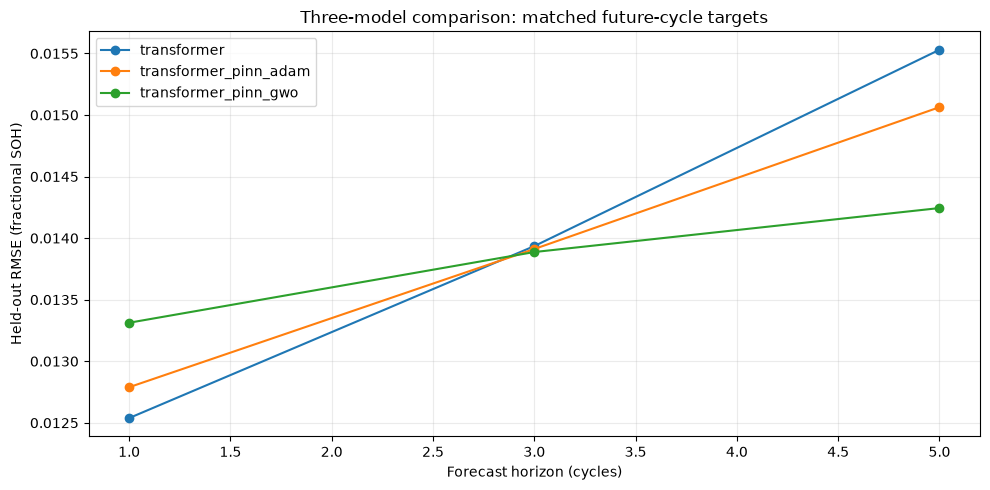

,split,model,monotonic_violation_fraction,mono_penalty,smooth_penalty
0,test,transformer,0.857143,5.156629e-06,5.535758e-07
1,test,transformer_pinn_adam,0.799128,2.668100e-06,5.451369e-07
2,test,transformer_pinn_gwo,0.382964,2.924213e-07,5.197945e-07
3,validation,transformer,0.851218,5.516093e-06,5.547057e-07
4,validation,transformer_pinn_adam,0.800415,2.883094e-06,5.471044e-07
5,validation,transformer_pinn_gwo,0.382063,3.805873e-07,5.240715e-07


In [12]:
test_plot=summary.query('split=="test"')
fig,ax=plt.subplots(figsize=(10,5))
for model,group in test_plot.groupby('model'):
    ax.plot(group.horizon,group.RMSE_mean,marker='o',label=model)
ax.set(xlabel="Forecast horizon (cycles)",ylabel="Held-out RMSE (fractional SOH)",title="Three-model comparison: matched future-cycle targets")
ax.grid(alpha=.25);ax.legend();fig.tight_layout();fig.savefig(OUT_DIR/"test_RMSE_by_horizon.png",dpi=160)
plt.show()

phys_summary=(physics_df.groupby(["split","model"],as_index=False)
              .agg(monotonic_violation_fraction=("monotonic_violation_fraction","mean"),
                   mono_penalty=("mono_penalty","mean"),smooth_penalty=("smooth_penalty","mean")))
phys_summary.to_csv(OUT_DIR/"physics_summary.csv",index=False)
display(phys_summary)


## 13 · Reuse a saved checkpoint for inference

Example: load the validation-selected checkpoint and fold-specific preprocessing. The input must contain the same ordered five feature columns and valid 12-cycle observation history. The saved model predicts all three horizons in one forward pass.

In [13]:
# Reusable helper, does not run inference automatically.
def load_saved_checkpoint(checkpoint_path, device=DEVICE):
    checkpoint=torch.load(checkpoint_path,map_location=device,weights_only=False)
    model=SOHTransformer(**checkpoint["model_config"]).to(device)
    model.load_state_dict(checkpoint["state_dict"])
    model.eval()
    return model,checkpoint

print("To load a model, call load_saved_checkpoint(path_to_pt).")

To load a model, call load_saved_checkpoint(path_to_pt).


## Interpretation and next steps

A strong paper needs **more than** three existing components. Compare validation-selected models across all held-out cells, check errors near real SOH fluctuations, and show whether physics-guided training reduces unjustified forecast increases **without sacrificing accuracy**. Run an equal-budget random search against GWO to establish whether GWO provides value. For cross-family claims, reconstruct and harmonize CS2/CX2/PL features and protocols rather than mixing nominal-capacity definitions.

**Do not report smoke-mode metrics.** The model selected via validation might not be the one with the lowest test RMSE; keep that distinction intact.